Analyze confusion matrices in detail, calculating false positive/negative rates and assessing model misclassification patterns to diagnose systematic prediction errors and inform model refinement.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 900

In [10]:
white_cell_count = np.random.normal(9, 3, n_samples).clip(3, 25).round(1)
crp_level = np.random.exponential(scale=15, size=n_samples).round(1) # C-Reactive Protein
procalcitonin = np.random.exponential(scale=0.8, size=n_samples).round(2)
body_temp = np.random.normal(37.8, 1.2, n_samples).clip(36.0, 41.0).round(1)
cough_severity = np.random.randint(1, 10, n_samples)

In [11]:
logits_0 = 3.0 - 0.3 * white_cell_count - 0.1 * crp_level - 1.5 * procalcitonin
logits_1 = -2.0 + 0.25 * white_cell_count + 0.08 * crp_level + 2.0 * procalcitonin
logits_2 = -1.0 + 0.10 * white_cell_count + 0.05 * crp_level - 0.8 * procalcitonin + 0.5 * body_temp

In [12]:
logits = np.column_stack([logits_0, logits_1, logits_2])
exp_logits = np.exp(logits - np.max(logits, axis=1, keepdims=True))
probs = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)

In [13]:
target = np.array([np.random.choice([0, 1, 2], p=p) for p in probs])

In [14]:
df_diag = pd.DataFrame({
    'white_cell_count': white_cell_count,
    'crp_level': crp_level,
    'procalcitonin': procalcitonin,
    'body_temp': body_temp,
    'cough_severity': cough_severity,
    'diagnosis': target
})

In [15]:
print("Dataset Shape:", df_diag.shape)
print("Diagnostic Class Distribution:\n", df_diag['diagnosis'].value_counts())

Dataset Shape: (900, 6)
Diagnostic Class Distribution:
 diagnosis
2    900
Name: count, dtype: int64


In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix

In [65]:
np.random.seed(42)
n_samples = 900

In [66]:
white_cell_count = np.random.normal(9, 3, n_samples).clip(3, 25).round(1)
crp_level = np.random.exponential(scale=15, size=n_samples).round(1)
procalcitonin = np.random.exponential(scale=0.8, size=n_samples).round(2)
body_temp = np.random.normal(37.8, 1.2, n_samples).clip(36.0, 41.0).round(1)
cough_severity = np.random.randint(1, 10, n_samples)

In [ ]:
target_multi = np.random.choice([0, 1, 2], size=n_samples, p=[0.35, 0.35, 0.30])

In [85]:
df_diag = pd.DataFrame({
    'white_cell_count': white_cell_count,
    'crp_level': crp_level,
    'procalcitonin': procalcitonin,
    'body_temp': body_temp,
    'cough_severity': cough_severity,
    'diagnosis': target_multi
})

In [86]:
X_diag = df_diag.drop(columns=['diagnosis'])
y_diag = df_diag['diagnosis']
class_names = ['Healthy', 'Bacterial Pneumonia', 'Viral Pneumonia']


In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X_diag, y_diag, test_size=0.30, random_state=42, stratify=y_diag
)

In [88]:
model = HistGradientBoostingClassifier(max_iter=100, random_state=42)
model.fit(X_train, y_train)

HistGradientBoostingClassifier(random_state=42)

In [89]:
y_pred = model.predict(X_test)
cm_raw = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

In [90]:
per_class_metrics = []
for i, class_label in enumerate(class_names):
    TP = cm_raw[i, i]
    FN = np.sum(cm_raw[i, :]) - TP
    FP = np.sum(cm_raw[:, i]) - TP
    TN = np.sum(cm_raw) - (TP + FN + FP)
    
    fpr = FP / (FP + TN) if (FP + TN) > 0 else 0
    fnr = FN / (TP + FN) if (TP + FN) > 0 else 0
    
    per_class_metrics.append({
        'Diagnostic Class': class_label,
        'FPR (Alpha Risk)': round(fpr, 4),
        'FNR (Beta Risk)': round(fnr, 4)
    })

In [91]:
df_error_rates = pd.DataFrame(per_class_metrics).set_index('Diagnostic Class')

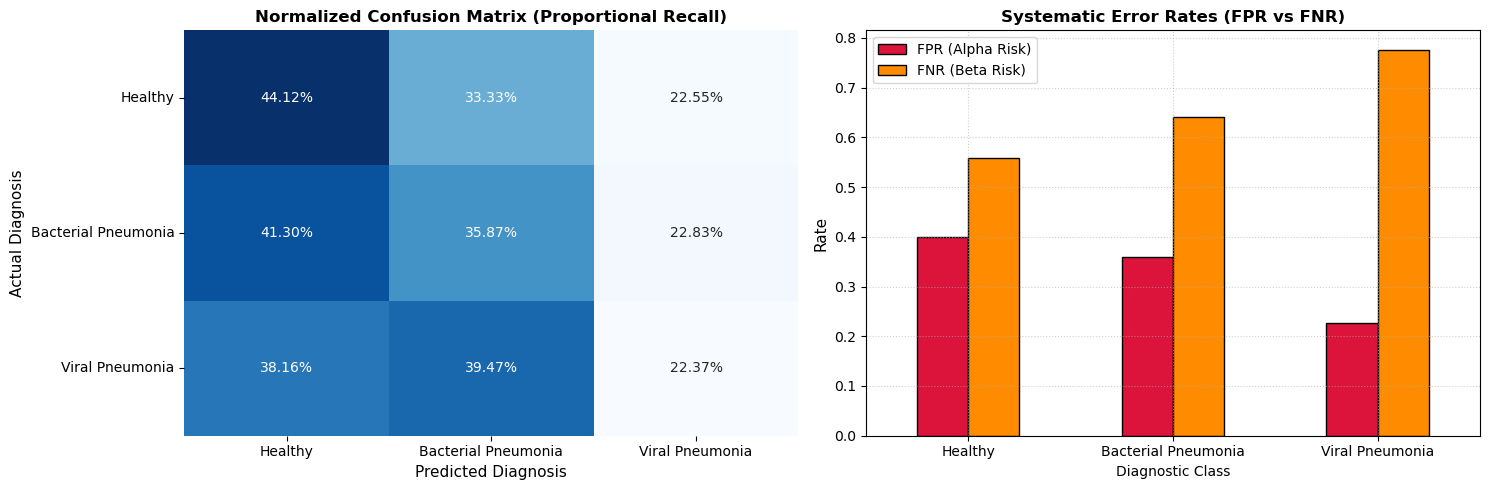

In [92]:
cm_norm = cm_raw.astype('float') / cm_raw.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(
    cm_norm, 
    annot=True, 
    fmt='.2%', 
    cmap='Blues', 
    xticklabels=class_names, 
    yticklabels=class_names, 
    ax=axes[0],
    cbar=False
)
axes[0].set_title("Normalized Confusion Matrix (Proportional Recall)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted Diagnosis", fontsize=11)
axes[0].set_ylabel("Actual Diagnosis", fontsize=11)

df_error_rates[['FPR (Alpha Risk)', 'FNR (Beta Risk)']].plot(
    kind='bar', 
    ax=axes[1], 
    color=['crimson', 'darkorange'], 
    edgecolor='black'
)
axes[1].set_title("Systematic Error Rates (FPR vs FNR)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Rate", fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()